In [1]:
import json, time
import numpy as np, h5py, pandas as pd
import matplotlib.pyplot as plt
from mem import analysis as A, config as cfg, validation as V

EVENTS = "data/events_s40.h5"          # full sample: "data/events.h5"
LUMI0 = 500.0                          # fb^-1, luminosity of the paper's fits
LUMIS = np.array([300, 500, 1000, 1500, 2000, 2500, 3000.0])
PT_BINS = np.arange(500, 3501, 100)    # paper binning (Eq. 5.13)
HYPS = ["Scalar", "VLF", "Zp01", "Zp20"]
TRUTHS = ["Scalar", "VLF", "Zp20", "Zp01"]
LABEL = {"Scalar": "Scalar", "VLF": "VLF", "Zp01": "$Z'$ narrow", "Zp20": "$Z'$ broad", "SM": "SM"}
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

S = A.Sample(EVENTS)
with h5py.File(EVENTS) as h:
    chan = h["channel"][:]
    w_lhe = h["w_lhe"][:]
    alphas0 = h["alphas0"][:]
    nvec = h["n"][:]
print(f"{len(S.w)} events, sigma = {S.sigma:.5f} pb, N_eff = {S.n_eff:.0f}")

58992 events, sigma = 1.42740 pb, N_eff = 13119


In [2]:
# Published results (arXiv:2611.08459): Tables 2-4 (L = 500 fb^-1) and Fig. 12 (L = 3 ab^-1).
# theta = y_DM^2 (Scalar, VLF) or g_q g_t (Z').
PAPER_FITS = {
    "Scalar": {"Scalar": (1510.2, 7.6**2, 0.009), "VLF": (1744.5, 4.6**2, 0.85),
               "Zp01": (2500.1, -0.016*0.35, 23.3), "Zp20": (2882.0, -0.030*1.58, 10.5)},
    "VLF":    {"VLF": (1505.3, 3.8**2, 0.008), "Scalar": (1247.0, 5.9**2, 0.83),
               "Zp01": (2908.9, -0.019*0.35, 22.2), "Zp20": (2811.0, -0.028*1.58, 9.3)},
    "Zp20":   {"Zp20": (3009.8, -0.034*1.58, 0.06), "Zp01": (2915.9, -0.023*0.35, 11.0),
               "VLF": (1518.0, 3.6**2, 11.2), "Scalar": (1336.1, 6.0**2, 10.3)},
}
PAPER_YIELD = {"Scalar": ("Scalar", 1510.2, 7.6**2, 3032), "VLF": ("VLF", 1505.3, 3.8**2, 3465),
               "Zp20": ("Zp20", 3009.8, -0.034*1.58, 1372)}       # signal events in 0.5 < pT < 3.5 TeV, 500 fb^-1
PAPER_Z3000 = {  # [H0][H1]
    "Scalar": {"VLF": 2.2, "Zp01": 12.5, "Zp20": 7.8}, "VLF": {"Scalar": 2.2, "Zp01": 12.4, "Zp20": 8.2},
    "Zp01": {"Scalar": 11.7, "VLF": 11.5, "Zp20": 8.0}, "Zp20": {"Scalar": 7.9, "VLF": 7.5, "Zp01": 9.4}}

## Sample and weight normalisation

The SM sample is a fixed-order aMC@NLO run (`[QCD NP]` at $y_{\rm DM}=0$, i.e. the LO Born) with an $m_{t\bar t}$ bias, signed NNPDF2.3 PDFs, and $\mu_R=\mu_F=H_T/2$.



In [3]:
norm = S.meta["norm"]
print(json.dumps({k: norm[k] for k in ("sigma_summary", "sigma_lo", "sigma_lo_err", "kappa")}, indent=1))
print(f"sigma_LO total = {sum(norm['sigma_lo'].values()):.5f} pb   vs summary.txt {norm['sigma_summary']} pb")
Ss = A.Sample(EVENTS, flux_mode="signed")
print(f"generator (signed PDFs): negative-weight events {np.mean(Ss.w < 0):.2%}, share of sigma "
      f"{Ss.w[Ss.w < 0].sum() / Ss.sigma:.1e}, median max(x1,x2) {np.median(np.maximum(Ss.x1, Ss.x2)[Ss.w < 0]):.2f}")
print(f"nominal (clipped PDFs, f -> max(f, 0)): {S.n_dropped} events removed ({S.n_dropped / len(Ss.w):.2%}), "
      f"sigma = {S.sigma:.5f} pb (signed {Ss.sigma:.5f}), min weight {S.w.min():.1e}, "
      f"r_T(Scalar) in [{S.r_benchmark('Scalar').min():.3f}, {S.r_benchmark('Scalar').max():.3f}] "
      f"(signed: up to {Ss.r_benchmark('Scalar').max():.2f})")

{
 "sigma_summary": 1.424,
 "sigma_lo": {
  "gg": 0.9764899359011249,
  "qq": 0.4496284719499506
 },
 "sigma_lo_err": {
  "gg": 0.0007406363048525443,
  "qq": 0.0002680426337974907
 },
 "kappa": {
  "gg": 386.90928779411036,
  "qq": 360.8132418890978
 }
}
sigma_LO total = 1.42612 pb   vs summary.txt 1.424 pb
generator (signed PDFs): negative-weight events 2.20%, share of sigma -4.7e-04, median max(x1,x2) 0.75
nominal (clipped PDFs, f -> max(f, 0)): 1152 events removed (1.92%), sigma = 1.42740 pb (signed 1.42612), min weight 6.6e-25, r_T(Scalar) in [0.932, 1.166] (signed: up to 2.68)


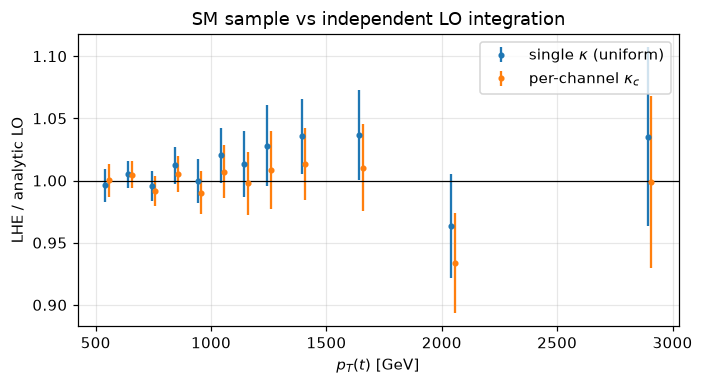

In [4]:
# Independent LO integration (cached): shape test of the two normalisations against it
import os
bins = np.array([500, 600, 700, 800, 900, 1000, 1100, 1200, 1300, 1500, 1800, 2300, 3500.])
cache = "data/lo_integration_pt.npz"   # LO histogram, 16M points, NO m_tt ceiling (must match the generation cuts)
c = np.load(cache) if os.path.exists(cache) else None
if c is None or len(c["bins"]) != len(bins) or not np.allclose(c["bins"], bins):
    lo = V.lo_integration(16_000_000, seed=7)        # about 2 min
    np.savez(cache, *V.hist_with_err(lo["pt"], lo["w"], bins), bins=bins)
    c = np.load(cache)
h_lo, e_lo = c["arr_0"], c["arr_1"]
w_single = w_lhe * norm["sigma_summary"] / w_lhe.sum()
fig, ax = plt.subplots(figsize=(6.5, 3.6))
xc = 0.5 * (bins[1:] + bins[:-1])
for w, lab, off in [(w_single, r"single $\kappa$ (uniform)", -8), (Ss.w, r"per-channel $\kappa_c$", 8)]:
    h, e = V.hist_with_err(Ss.pt, w, bins)
    ax.errorbar(xc + off, h / h_lo, yerr=np.hypot(e / h, e_lo / h_lo) * h / h_lo, fmt="o", ms=3, label=lab)
ax.axhline(1, c="k", lw=0.8); ax.set_xlabel(r"$p_T(t)$ [GeV]"); ax.set_ylabel("LHE / analytic LO"); ax.legend()
ax.set_title("SM sample vs independent LO integration"); plt.tight_layout()

## Matrix-element checks

* the MadLoop Born against the analytic LO formulas, and the Scalar library against the VLF library;
* the $\mu_R$ independence of $\rho_c=I_c/|M_{\rm SM}|^2$ (exact $\alpha_s^2$ scaling, which the scale variations rely on);
* beam-swap symmetry of the $q\bar q$ interference (so the two orientations combine into $F_q$);
* the $Z'$ Breit-Wigner factorisation $B=K/D$, $A=[(\hat s-M^2)R+M\Gamma I]/D$: a direct evaluation at $(M,\Gamma)$ points not used in the extraction;
* MadLoop stability flags and re-evaluation of the first events (first-call artefacts).



In [5]:
rows = []
gg_an, qq_an = V.born_lo(S.mtt, nvec[S.mask, 2], alphas0[S.mask])
with h5py.File(S.me_file("Scalar")) as hs, h5py.File(S.me_file("VLF")) as hv, h5py.File(S.me_file("Zprime")) as hz:
    bs, bv = hs["born"][:][S.mask], hv["born"][:][S.mask]
    rows.append(("Born gg: MadLoop / analytic - 1", np.max(np.abs(bs[:, 0] / gg_an - 1))))
    rows.append(("Born qq: MadLoop / analytic - 1", np.max(np.abs(bs[:, 1] / qq_an - 1))))
    rows.append(("Born: Scalar lib / VLF lib - 1", np.max(np.abs(bs / bv - 1))))
    for name, h in (("Scalar", hs), ("VLF", hv)):
        i0 = 0
        for ch in ("gg", "qq"):
            st = h[f"checks/scale_{ch}"][:]
            rows.append((f"{name} rho_{ch}(mu_R = mu0/2, 2mu0) / rho(mu0) - 1",
                         np.max(np.abs(st / h[f"rho_{ch}"][i0, :len(st)][:, None] - 1))))
        sw = h["checks/swap_qq"][:]
        rows.append((f"{name} qq beam swap: rho(p2,p1)/rho(p1,p2) - 1", np.max(np.abs(sw[1, 1] / sw[0, 1] - 1))))
        rows.append((f"{name} unstable MadLoop points (flag)", int(h["flag"][:].sum())))
        rows.append((f"{name} max re-evaluation deviation", h.attrs["recheck_max"]))
    rows.append(("Z' max deviation from Breit-Wigner form", hz.attrs["bw_dev_max"]))
pd.DataFrame(rows, columns=["check", "value"])

,check,value
0,Born gg: MadLoop / analytic - 1,8.3199e-07
1,Born qq: MadLoop / analytic - 1,7.4385e-15
2,Born: Scalar lib / VLF lib - 1,4.4409e-16
3,"Scalar rho_gg(mu_R = mu0/2, 2mu0) / rho(mu0) - 1",5.8705e-08
4,"Scalar rho_qq(mu_R = mu0/2, 2mu0) / rho(mu0) - 1",5.6562e-08
5,"Scalar qq beam swap: rho(p2,p1)/rho(p1,p2) - 1",4.0783e-12
6,Scalar unstable MadLoop points (flag),0.0000e+00
7,Scalar max re-evaluation deviation,6.9514e-08
8,"VLF rho_gg(mu_R = mu0/2, 2mu0) / rho(mu0) - 1",5.7018e-08
9,"VLF rho_qq(mu_R = mu0/2, 2mu0) / rho(mu0) - 1",5.7852e-08


## BSM normalisation checks

**(a) Against the paper.** Signal yields in $0.5<p_T<3.5$ TeV at 500 fb$^{-1}$ (Tables 2-4), evaluated at the paper's best-fit parameters of the true model. Our sample also has the generation cut $m_{t\bar t}<4.6$ TeV, so it has no events above $p_T\simeq2.3$ TeV.

**(b) Against the Scalar aMC@NLO run** of the same benchmark (`processFolders/Scalar/pp2ttbar_gs4_ydm2/Events/bias_13_6TeV_fiducial_pT`). Its precise numbers are the *biased* totals $\int b\,d\sigma$ (0.07% MC error): $b(m_{t\bar t})$ is the bias of that folder with $m_{\tilde t}=1500$ GeV, which reproduces the SM biased total. Its histogram value (1.429 pb) is rounded to $10^{-3}$.

In [6]:
rows = []
for truth, (model, M, th, y_paper) in PAPER_YIELD.items():
    r = S.r(model, th, M)
    y = A.FB * LUMI0 * np.sum(S.w * (r - 1))
    rows.append((truth, M, th, y_paper, y, y / y_paper))
pd.DataFrame(rows, columns=["truth", "M", "theta", "paper yield", "this work", "ratio"])

,truth,M,theta,paper yield,this work,ratio
0,Scalar,1510.2,57.7600,3032,3149.1833,1.0386
1,VLF,1505.3,14.4400,3465,3548.9560,1.0242
2,Zp20,3009.8,-0.0537,1372,1345.9423,0.9810


In [7]:
def bias_scalar(mtt, mst=1500.0):     # Source/mtt_bias_NLO.f of the Scalar folder (peak_loc > 2900 branch)
    pk = 2.05 * mst
    b1, b2, d3 = 3510 / 3075 * pk, 3770 / 3075 * pk, 3207 / 3075 * pk
    return np.where(mtt < b1, (mtt / pk) ** 3.3, np.where(mtt < b2, (mtt / pk) ** 2.0, (mtt / d3) ** 8.0))

b = bias_scalar(S.mtt); rT = S.r_benchmark("Scalar")
# res_1.txt of the two runs (no m_tt ceiling in either)
amc = {"SM": {"gg": 0.0998611, "qq": 0.0252763 + 0.0252356}, "Scalar": {"gg": 0.0998529, "qq": 0.0262219 + 0.0261851}}
rows = []
with h5py.File(S.me_file("Scalar")) as h:
    i = list(h.attrs["masses"]).index(1500)
    rho = {"gg": h["rho_gg"][i][S.mask], "qq": h["rho_qq"][i][S.mask]}
for ch, frac in (("gg", S.omega_gg), ("qq", 1 - S.omega_gg)):
    sm = S.w * b * frac
    bsm = sm * cfg.BENCHMARKS["Scalar"]["theta"] * rho[ch]
    rows.append((ch, sm.sum(), amc["SM"][ch], bsm.sum() / sm.sum(), amc["Scalar"][ch] / amc["SM"][ch] - 1))
pd.DataFrame(rows, columns=["channel", "biased SM (this)", "biased SM (aMC)", "BSM/SM biased (this)", "BSM/SM biased (aMC)"])

,channel,biased SM (this),biased SM (aMC),BSM/SM biased (this),BSM/SM biased (aMC)
0,gg,0.1001,0.0999,0.0002,-8.2114e-05
1,qq,0.0510,0.0505,0.0402,3.7518e-02


## Binned analysis: reproduction of the paper

Same events, but the cells are the paper's $p_T$ bins. Step A minimises the binned Poisson deviance (paper Eq. 5.1-5.5); Step B is Eq. 5.9. The masses come from a profile over the 100 GeV grid with a parabola through the three lowest points.

In [8]:
def run_all(bins, lumi=LUMI0, sample=S, truths=TRUTHS, verbose=False):
    out = {}
    for t in truths:
        t0 = time.time()
        out[t] = A.run_analysis(sample, t, HYPS + ["SM"], lumi=lumi, bins=bins, verbose=verbose)
        print(f"  truth {t:7s} done in {time.time() - t0:.0f}s")
    return out

def fit_table(res, truth, paper=True):
    rows = []
    for h in HYPS:
        f = res[truth]["fits"][h]
        row = dict(hypothesis=h, M=f["M"], theta=f["theta"], chi2=f["chi2"])
        if paper and truth in PAPER_FITS and h in PAPER_FITS[truth]:
            Mp, tp, cp = PAPER_FITS[truth][h]
            row.update(M_paper=Mp, theta_paper=tp, chi2_paper=cp)
        rows.append(row)
    return pd.DataFrame(rows).set_index("hypothesis")

print("binned:"); RB = run_all(PT_BINS)

binned:
  truth Scalar  done in 0s


  truth VLF     done in 0s
  truth Zp20    done in 0s


  truth Zp01    done in 0s


In [9]:
for t in ["Scalar", "VLF", "Zp20"]:
    print(f"truth = {t}  (binned, L = {LUMI0:.0f} fb^-1)")
    display(fit_table(RB, t))

truth = Scalar  (binned, L = 500 fb^-1)


,M,theta,chi2,M_paper,theta_paper,chi2_paper
hypothesis,,,,,,
Scalar,1500.0000,56.2500,-8.9511e-11,1510.2,57.7600,0.009
VLF,1739.9960,20.5036,7.9839e-01,1744.5,21.1600,0.850
Zp01,2900.0000,-0.0069,2.3296e+01,2500.1,-0.0056,23.300
Zp20,2894.0695,-0.0466,1.0685e+01,2882.0,-0.0474,10.500


truth = VLF  (binned, L = 500 fb^-1)


,M,theta,chi2,M_paper,theta_paper,chi2_paper
hypothesis,,,,,,
Scalar,1262.2969,36.0476,8.6104e-01,1247.0,34.8100,0.830
VLF,1500.0000,14.4400,-5.5278e-11,1505.3,14.4400,0.008
Zp01,2900.0000,-0.0071,2.2086e+01,2908.9,-0.0066,22.200
Zp20,2822.1738,-0.0454,1.0040e+01,2811.0,-0.0442,9.300


truth = Zp20  (binned, L = 500 fb^-1)


,M,theta,chi2,M_paper,theta_paper,chi2_paper
hypothesis,,,,,,
Scalar,1348.4992,37.6270,1.1096e+01,1336.1,36.0000,10.30
VLF,1500.0000,12.4211,1.2017e+01,1518.0,12.9600,11.20
Zp01,2900.0000,-0.0087,8.5480e+00,2915.9,-0.0080,11.00
Zp20,3000.0000,-0.0553,-4.4132e-11,3009.8,-0.0537,0.06


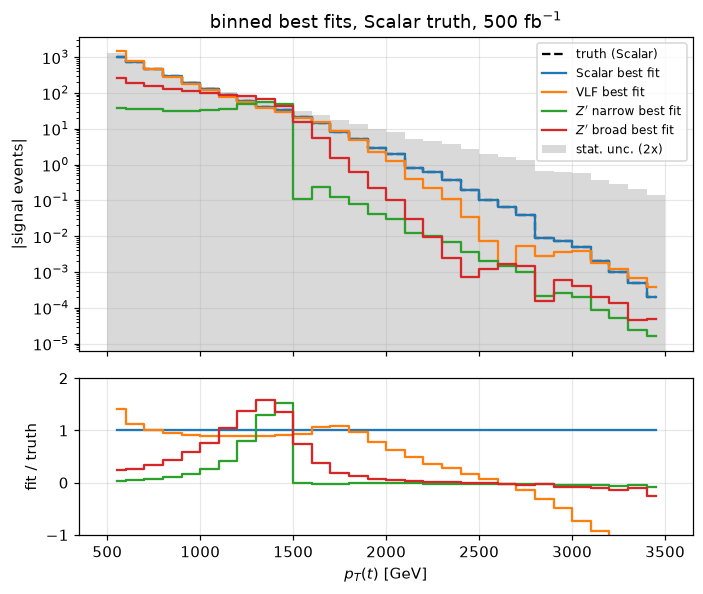

In [10]:
def plot_fig9(res, truth, title):
    # Fig. 9 analogue: BSM p_T distribution of the best fits, ratio to the truth
    cells = A.Cells(S, PT_BINS)
    nT = cells.counts(S.r_benchmark(truth) - 1) * A.FB * LUMI0
    ntot = cells.counts(S.r_benchmark(truth)) * A.FB * LUMI0
    xc = 0.5 * (PT_BINS[1:] + PT_BINS[:-1])
    fig, (a0, a1) = plt.subplots(2, 1, figsize=(6.5, 5.5), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
    a0.bar(xc, 2 * np.sqrt(np.abs(ntot)), width=100, color="0.85", label="stat. unc. (2x)")
    a0.step(xc, np.abs(nT), where="mid", c="k", ls="--", label=f"truth ({LABEL[truth]})")
    for h in HYPS:
        f = res[truth]["fits"][h]
        n = cells.counts(A.r_of(S, f) - 1) * A.FB * LUMI0
        a0.step(xc, np.abs(n), where="mid", label=f"{LABEL[h]} best fit")
        with np.errstate(divide="ignore", invalid="ignore"):
            a1.step(xc, n / nT, where="mid")
    a0.set_yscale("log"); a0.set_ylabel("|signal events|"); a0.legend(fontsize=8); a0.set_title(title)
    a1.set_ylim(-1, 2); a1.set_xlabel(r"$p_T(t)$ [GeV]"); a1.set_ylabel("fit / truth"); plt.tight_layout()

plot_fig9(RB, "Scalar", "binned best fits, Scalar truth, 500 fb$^{-1}$")

## Unbinned analysis (Step A, Step B)

One cell per event: $\chi^2_H=2L\sum_j w_j[r_H-r_T+r_T\ln(r_T/r_H)]$ and $q_A=2L\sum_j w_j[r_0-r_1+r_1\ln(r_1/r_0)]$.

In [11]:
print("unbinned:"); RU = run_all(None)
for t in ["Scalar", "VLF", "Zp20"]:
    print(f"truth = {t}  (unbinned, L = {LUMI0:.0f} fb^-1)")
    display(fit_table(RU, t))

unbinned:


  truth Scalar  done in 3s


  truth VLF     done in 3s


  truth Zp20    done in 3s


  truth Zp01    done in 3s
truth = Scalar  (unbinned, L = 500 fb^-1)


,M,theta,chi2,M_paper,theta_paper,chi2_paper
hypothesis,,,,,,
Scalar,1500.0000,56.2500,-1.6168e-12,1510.2,57.7600,0.009
VLF,1739.6997,20.4868,1.3458e+00,1744.5,21.1600,0.850
Zp01,3300.0000,-0.0029,3.9090e+01,2500.1,-0.0056,23.300
Zp20,3219.0615,-0.0481,1.6800e+01,2882.0,-0.0474,10.500


truth = VLF  (unbinned, L = 500 fb^-1)


,M,theta,chi2,M_paper,theta_paper,chi2_paper
hypothesis,,,,,,
Scalar,1293.5115,38.2400,1.8638e+00,1247.0,34.8100,0.830
VLF,1500.0000,14.4400,-1.6575e-12,1505.3,14.4400,0.008
Zp01,3037.7952,-0.0030,3.7780e+01,2908.9,-0.0066,22.200
Zp20,3008.7968,-0.0452,1.3498e+01,2811.0,-0.0442,9.300


truth = Zp20  (unbinned, L = 500 fb^-1)


,M,theta,chi2,M_paper,theta_paper,chi2_paper
hypothesis,,,,,,
Scalar,1300.0000,37.0427,2.2033e+01,1336.1,36.0000,10.30
VLF,1500.0000,13.8646,1.9763e+01,1518.0,12.9600,11.20
Zp01,3008.5172,-0.0040,4.7520e+01,2915.9,-0.0080,11.00
Zp20,3000.0000,-0.0553,-4.3362e-13,3009.8,-0.0537,0.06


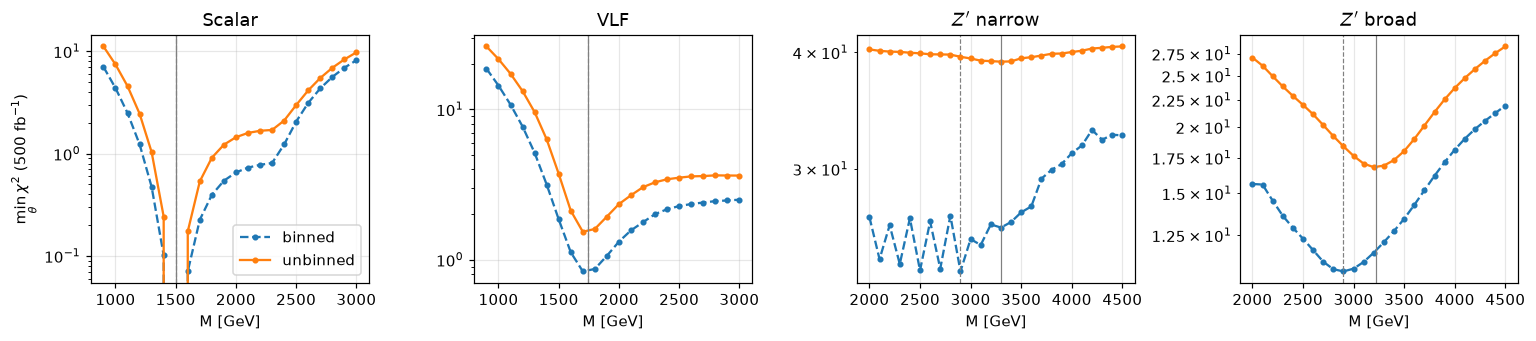

In [12]:
# Step-A profiles chi^2(M) (theta profiled), binned vs unbinned, Scalar truth
fig, axs = plt.subplots(1, 4, figsize=(14, 3.2))
for ax, h in zip(axs, HYPS):
    for res, lab, ls in ((RB, "binned", "--"), (RU, "unbinned", "-")):
        f = res["Scalar"]["fits"][h]
        ax.plot(f["grid"], f["profile"][:, 1], ls, marker=".", label=lab)
        ax.axvline(f["M"], ls=ls, c="0.5", lw=0.8)
    ax.set_title(LABEL[h]); ax.set_xlabel("M [GeV]"); ax.set_yscale("log")
axs[0].set_ylabel(r"$\min_\theta \chi^2$ (500 fb$^{-1}$)"); axs[0].legend(); plt.tight_layout()

## Binned vs unbinned

Without systematics $q_A\propto L$, so $Z_A(L)=Z_A(L_0)\sqrt{L/L_0}$ and the best fits do not depend on $L$.

In [13]:
def z_table(res, lumi):
    return pd.DataFrame({LABEL[t]: {LABEL[h]: z * np.sqrt(lumi / LUMI0) for h, z in res[t]["Z"].items()}
                         for t in res}).loc[[LABEL[h] for h in HYPS + ["SM"]]]

print("Z_A at 500 fb^-1  [rows: tested H0, columns: truth H1]")
display(pd.concat({"binned": z_table(RB, 500), "unbinned": z_table(RU, 500)}, axis=1))
print("Z_A at 3 ab^-1")
paper = pd.DataFrame({LABEL[t]: {LABEL[h]: PAPER_Z3000[h].get(t, np.nan) for h in HYPS} for t in TRUTHS})
display(pd.concat({"paper (Fig. 12)": paper, "binned": z_table(RB, 3000).loc[paper.index],
                   "unbinned": z_table(RU, 3000).loc[paper.index]}, axis=1))

Z_A at 500 fb^-1  [rows: tested H0, columns: truth H1]


binned                                unbinned          \
             Scalar     VLF $Z'$ broad $Z'$ narrow   Scalar     VLF   
Scalar          NaN  0.9279     3.3310      1.0486      NaN  1.3652   
VLF          0.8935     NaN     3.4665      1.0367   1.1601     NaN   
$Z'$ narrow  4.8266  4.6995     2.9237         NaN   6.2522  6.1465   
$Z'$ broad   3.2688  3.1686        NaN      0.7062   4.0987  3.6740   
SM           5.9912  6.0147     6.2633      1.2861   6.4211  6.4630   

                                    
            $Z'$ broad $Z'$ narrow  
Scalar          4.6940      3.7083  
VLF             4.4456      3.6341  
$Z'$ narrow     6.8935         NaN  
$Z'$ broad         NaN      3.4157  
SM              7.6845      3.8158

Z_A at 3 ab^-1


paper (Fig. 12)                                binned           \
                     Scalar   VLF $Z'$ broad $Z'$ narrow   Scalar      VLF   
Scalar                  NaN   2.2        7.8        12.5      NaN   2.2729   
VLF                     2.2   NaN        8.2        12.4   2.1887      NaN   
$Z'$ narrow            11.7  11.5        8.0         NaN  11.8228  11.5115   
$Z'$ broad              7.9   7.5        NaN         9.4   8.0068   7.7615   

                                   unbinned                                  
            $Z'$ broad $Z'$ narrow   Scalar      VLF $Z'$ broad $Z'$ narrow  
Scalar          8.1593      2.5685      NaN   3.3441    11.4979      9.0834  
VLF             8.4912      2.5394   2.8416      NaN    10.8893      8.9016  
$Z'$ narrow     7.1616         NaN  15.3147  15.0558    16.8856         NaN  
$Z'$ broad         NaN      1.7298  10.0398   8.9994        NaN      8.3668

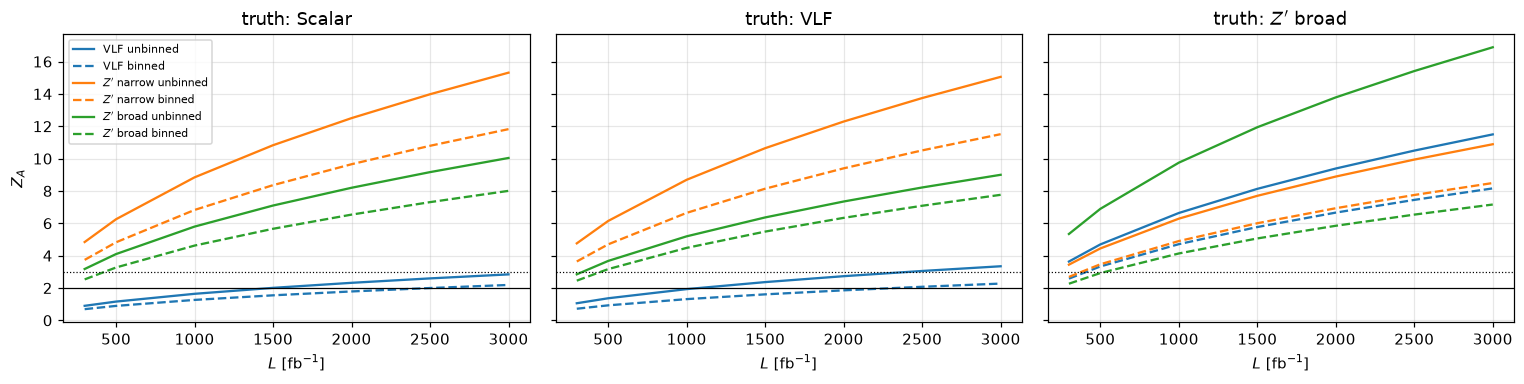

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, t in zip(axs, ["Scalar", "VLF", "Zp20"]):
    for k, h in enumerate([h for h in HYPS if h != t]):
        c = f"C{k}"
        ax.plot(LUMIS, RU[t]["Z"][h] * np.sqrt(LUMIS / LUMI0), c=c, label=f"{LABEL[h]} unbinned")
        ax.plot(LUMIS, RB[t]["Z"][h] * np.sqrt(LUMIS / LUMI0), c=c, ls="--", label=f"{LABEL[h]} binned")
    ax.axhline(2, c="k", lw=0.8); ax.axhline(3, c="k", lw=0.8, ls=":")
    ax.set_title(f"truth: {LABEL[t]}"); ax.set_xlabel(r"$L$ [fb$^{-1}$]")
axs[0].set_ylabel(r"$Z_A$"); axs[0].legend(fontsize=7); plt.tight_layout()

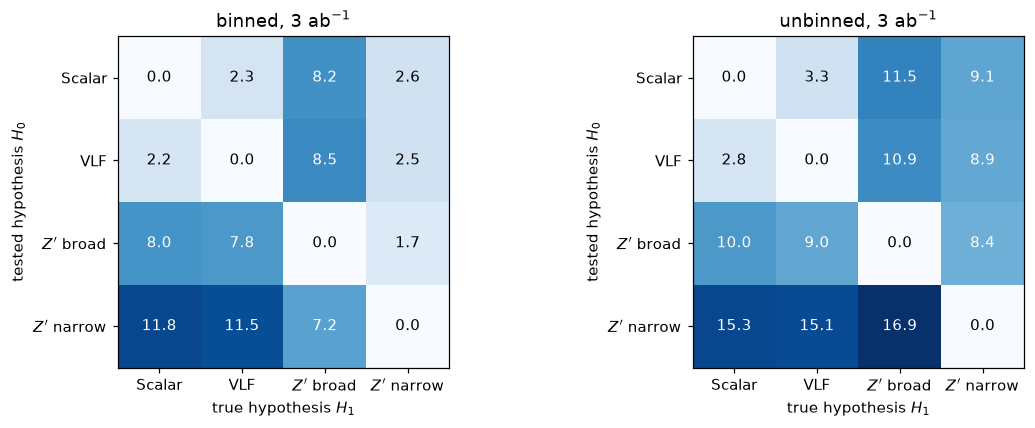

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, res, title in ((axs[0], RB, "binned"), (axs[1], RU, "unbinned")):
    M = np.array([[0.0 if h == t else res[t]["Z"][h] * np.sqrt(3000 / LUMI0) for t in TRUTHS] for h in TRUTHS])
    im = ax.imshow(M, cmap="Blues", vmin=0, vmax=max(13, M.max()))
    for i in range(len(TRUTHS)):
        for j in range(len(TRUTHS)):
            ax.text(j, i, f"{M[i, j]:.1f}", ha="center", va="center", color="w" if M[i, j] > 7 else "k")
    ax.set_xticks(range(4), [LABEL[t] for t in TRUTHS]); ax.set_yticks(range(4), [LABEL[t] for t in TRUTHS])
    ax.set_xlabel("true hypothesis $H_1$"); ax.set_ylabel("tested hypothesis $H_0$"); ax.grid(False)
    ax.set_title(f"{title}, 3 ab$^{{-1}}$")
plt.tight_layout()

### Consistency checks

1. **Log-sum inequality.** For the *same* pair $(r_0, r_1)$, the unbinned $q_A$ must be at least the binned one (exact for positive weights, which holds in the nominal $|f_af_b|$ convention).
2. **Step-B Asimov data.** $r_1$ (truth model at its own best fit) vs the benchmark $r_T$: identical up to the truth's best-fit deviance.
3. **Mixed analysis.** Binned Step-A fits with unbinned $q_A$, which separates the gain coming from the fit from the gain coming from the test.

In [16]:
cb, cu = A.Cells(S, PT_BINS), A.Cells(S, None)
rows = []
for t in ["Scalar", "VLF", "Zp20"]:
    r1u = RU[t]["r1"]; rT = S.r_benchmark(t)
    for h in [h for h in HYPS + ["SM"] if h != cfg.BENCHMARKS[t]["model"]]:
        r0 = A.r_of(S, RB[t]["fits"][h])                         # binned best fit of H0
        r1b = RB[t]["r1"]
        qb, qu = A.q_asimov(cb, r0, r1b, LUMI0), A.q_asimov(cu, r0, r1b, LUMI0)
        qT = A.q_asimov(cu, A.r_of(S, RU[t]["fits"][h]), rT, LUMI0)
        rows.append(dict(truth=t, H0=h, Z_binned=np.sqrt(qb), Z_unbinned_same_fits=np.sqrt(qu),
                         inequality_ok=qu >= qb * (1 - 1e-6), Z_unbinned=RU[t]["Z"][h], Z_unbinned_rT=np.sqrt(qT)))
pd.DataFrame(rows)

,truth,H0,Z_binned,Z_unbinned_same_fits,inequality_ok,Z_unbinned,Z_unbinned_rT
0,Scalar,VLF,0.8935,1.1599,True,1.1601,1.1601
1,Scalar,Zp01,4.8266,10.6761,True,6.2522,6.2522
2,Scalar,Zp20,3.2688,4.5002,True,4.0987,4.0987
3,Scalar,SM,5.9912,6.4211,True,6.4211,6.4211
4,VLF,Scalar,0.9279,1.3899,True,1.3652,1.3652
5,VLF,Zp01,4.6995,10.8528,True,6.1465,6.1465
6,VLF,Zp20,3.1686,4.0983,True,3.6740,3.6740
7,VLF,SM,6.0147,6.4630,True,6.4630,6.4630
8,Zp20,Scalar,3.3310,4.7374,True,4.6940,4.6940
9,Zp20,VLF,3.4665,4.4922,True,4.4456,4.4456


## Monte Carlo precision and robustness

* $N_{\rm eff}=(\sum w)^2/\sum w^2$ and a Poisson bootstrap of the events at fixed best fits (the spread of $Z_A$ from the finite MC sample).
* PDF convention: the nominal analysis sets every PDF to zero where it is negative, $f\to\max(f,0)$ (a 100% uncertainty on the NLO fit at large $x$; `ExtendedMEM.tex`, Eq. lumi), converting each generator weight with $D_c/D^{\rm signed}_c$ of its own integration channel ($gg$, $q\bar q$ with the quark from beam 1, or from beam 2: each generated event comes from one oriented channel); events whose weight becomes zero are removed. Variation: MadEvent's LO convention $|f_af_b|$ per ordered pair, with the same conversion. A second variation uses the signed products the generator sampled. There, $D_{\rm SM}\to0$ where the negative large-$x$ gluon cancels the $q\bar q$ term, and $r_H$ blows up (a PDF artefact).
* a large-$x$ cut, $\max(x_1,x_2)<0.4$, which removes the region where the NNPDF2.3 densities are negative and poorly constrained.

In [17]:
print(f"N = {len(S.w)},  N_eff = {S.n_eff:.0f},  N_eff(pT > 1.2 TeV) = "
      f"{S.w[S.pt > 1200].sum()**2 / np.sum(S.w[S.pt > 1200]**2):.0f}")
rows = []
for t in ["Scalar", "VLF", "Zp20"]:
    for h in [h for h in HYPS if h != cfg.BENCHMARKS[t]["model"]]:
        qb = A.bootstrap_q(cu, A.r_of(S, RU[t]["fits"][h]), RU[t]["r1"], LUMI0, nboot=300)
        zb = np.sqrt(np.clip(qb, 0, None))
        rows.append(dict(truth=t, H0=h, Z=RU[t]["Z"][h], Z_boot_mean=zb.mean(), Z_boot_std=zb.std()))
pd.DataFrame(rows)

N = 58992,  N_eff = 13119,  N_eff(pT > 1.2 TeV) = 3017


,truth,H0,Z,Z_boot_mean,Z_boot_std
0,Scalar,VLF,1.1601,1.1604,0.0065
1,Scalar,Zp01,6.2522,6.2521,0.0227
2,Scalar,Zp20,4.0987,4.0984,0.0146
3,VLF,Scalar,1.3652,1.3654,0.0102
4,VLF,Zp01,6.1465,6.1446,0.0235
5,VLF,Zp20,3.6740,3.6736,0.0111
6,Zp20,Scalar,4.6940,4.6902,0.0375
7,Zp20,VLF,4.4456,4.4419,0.0290
8,Zp20,Zp01,6.8935,6.8856,0.0567


In [18]:
variants = {"nominal": S, "|f_a f_b| (MadEvent LO)": A.Sample(EVENTS, flux_mode="abs"),
            "signed PDF products": A.Sample(EVENTS, flux_mode="signed"),
            "max(x1,x2) < 0.4": A.Sample(EVENTS, xcut=0.4)}
tabs = {}
for name, smp in variants.items():
    if name == "nominal":
        res = RU
    else:
        print(name); res = run_all(None, sample=smp, truths=["Scalar", "VLF", "Zp20"])
    tabs[name] = z_table(res, 3000)[[LABEL[t] for t in ["Scalar", "VLF", "Zp20"]]]
print("unbinned Z_A at 3 ab^-1 (fits redone in each variant)")
pd.concat(tabs, axis=1)

|f_a f_b| (MadEvent LO)


  truth Scalar  done in 3s


  truth VLF     done in 3s


  truth Zp20    done in 3s
signed PDF products


  truth Scalar  done in 3s


  truth VLF     done in 2s


  truth Zp20    done in 2s
max(x1,x2) < 0.4


  truth Scalar  done in 3s


  truth VLF     done in 3s


  truth Zp20    done in 3s
unbinned Z_A at 3 ab^-1 (fits redone in each variant)


nominal                     |f_a f_b| (MadEvent LO)           \
              Scalar      VLF $Z'$ broad                  Scalar      VLF   
Scalar           NaN   3.3441    11.4979                     NaN   3.3692   
VLF           2.8416      NaN    10.8893                  2.8623      NaN   
$Z'$ narrow  15.3147  15.0558    16.8856                 15.3935  15.1153   
$Z'$ broad   10.0398   8.9994        NaN                 10.0880   9.0220   
SM           15.7284  15.8310    18.8231                 15.8118  15.8959   

                       signed PDF products                      \
            $Z'$ broad              Scalar      VLF $Z'$ broad   
Scalar         11.4675                 NaN   3.4464    11.5745   
VLF            10.8521              2.8226      NaN    10.9286   
$Z'$ narrow    16.8608             15.3903  15.0470    16.9400   
$Z'$ broad         NaN             10.1497   8.9944        NaN   
SM             18.7926             15.9999  15.8127    18.8774   

            max(x1,x2) < 0.4                      
                      Scalar      VLF $Z'$ broad  
Scalar                   NaN   2.6836     9.4326  
VLF                   2.3754      NaN     9.2270  
$Z'$ narrow          12.7880  13.0152    13.6464  
$Z'$ broad            8.5149   8.1694        NaN  
SM                   13.1227  13.6044    15.1245